
<h1 style="text-align: center;">
    Prédiction du churn client - Telco Customer Churn
</h1>


<p align="center">
  <img src="illustration_churn.png" alt="Illustration du churn" width="10000">
</p>


**Objectif :** identifier les clients d'un opérateur télécom susceptibles de résilier leur abonnement (`Churn = Yes`) et comprendre les facteurs associés à leur départ.

**Données :** *Telco Customer Churn* - 7 043 clients, 21 colonnes (profil, services souscrits, contrat, facturation, ancienneté, churn).

**Plan du notebook**
1. Chargement des données
2. Exploration (EDA)
3. Nettoyage des données
4. Préparation : séparation train/test et prétraitement
5. Modèles de base : régression logistique et Random Forest
6. Seuil de décision, courbes Precision-Recall et ROC
7. Gestion du déséquilibre des classes
8. Tableau récapitulatif et choix du modèle final
9. Facteurs associés au départ des clients
10. Conclusion et recommandations

## 0. Importations des librairies

In [1]:
# --- Manipulation de données ---
import numpy as np
import pandas as pd

# --- Visualisation ---
import seaborn as sns
import matplotlib.pyplot as plt

# --- Prétraitement ---
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# --- Modèles ---
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# --- Rééchantillonnage ---
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

# --- Métriques d'évaluation ---
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,average_precision_score,
                             roc_curve, roc_auc_score,precision_recall_curve, confusion_matrix)

# --- Affichage d'image ---
from IPython.display import Image, display

## 1. Chargement des données

In [2]:
# Lecture du fichier CSV 
df = pd.read_csv("Telco-Customer-Churn.csv")

In [3]:
# Aperçu des 5 premières lignes
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Types des colonnes et nombre de valeurs non nulles
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
# Dimensions du jeu de données (lignes, colonnes)
df.shape

(7043, 21)

In [6]:
# Nombre de valeurs manquantes par colonne
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## 2. Exploration des données (EDA)

### 2.1 Variable cible : `Churn`

In [7]:
# Modalités de la variable cible
df["Churn"].unique()

array(['No', 'Yes'], dtype=object)

In [8]:
# Effectifs par modalité
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [9]:
# Proportions (en %) : la cible est déséquilibrée
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

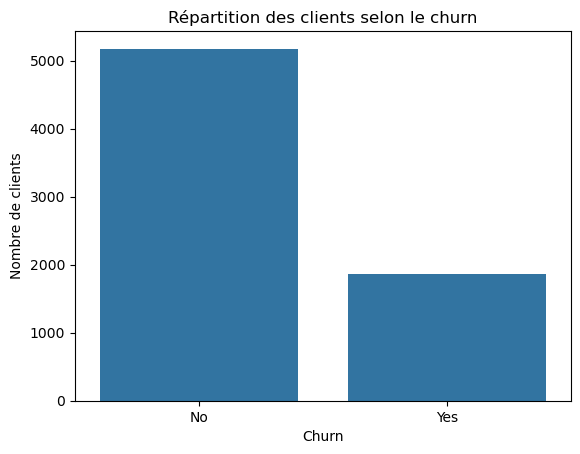

In [10]:
# Répartition des clients selon le churn
sns.countplot(data=df, x="Churn")
plt.title("Répartition des clients selon le churn")
plt.xlabel("Churn")
plt.ylabel("Nombre de clients")
plt.show()

### 2.2 Churn et ancienneté ("tenure")

In [11]:
# Durée moyenne d'abonnement (en mois) pour chaque catégorie de Churn
df.groupby("Churn")["tenure"].mean()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

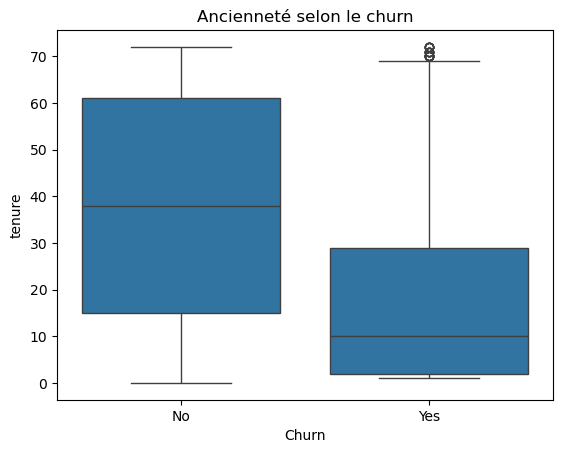

In [12]:
# Distribution de l'ancienneté selon le churn
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Ancienneté selon le churn")
plt.show()

### 2.3 Churn et type de contrat

In [13]:
# Nombre de clients dans chaque combinaison Contrat x Churn
df.groupby(["Contract", "Churn"]).size()

Contract        Churn
Month-to-month  No       2220
                Yes      1655
One year        No       1307
                Yes       166
Two year        No       1647
                Yes        48
dtype: int64

In [14]:
# Proportion de churn (en %) au sein de chaque type de contrat
churn_contract = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
churn_contract

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


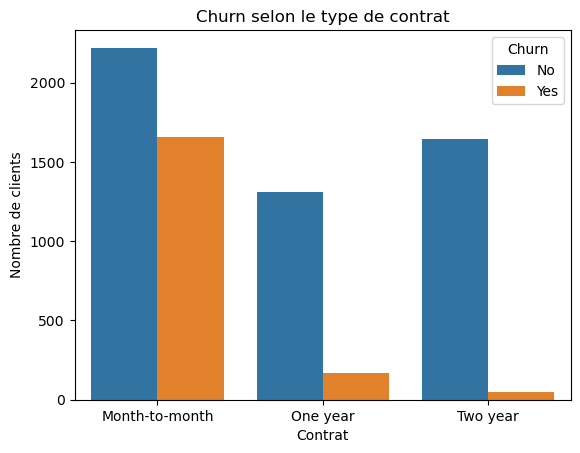

In [15]:
# Churn selon le type de contrat
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn selon le type de contrat")
plt.xlabel("Contrat")
plt.ylabel("Nombre de clients")
plt.show()

### 2.4 Churn et charges mensuelles ("MonthlyCharges")

In [16]:
# Charges mensuelles moyennes selon le churn
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

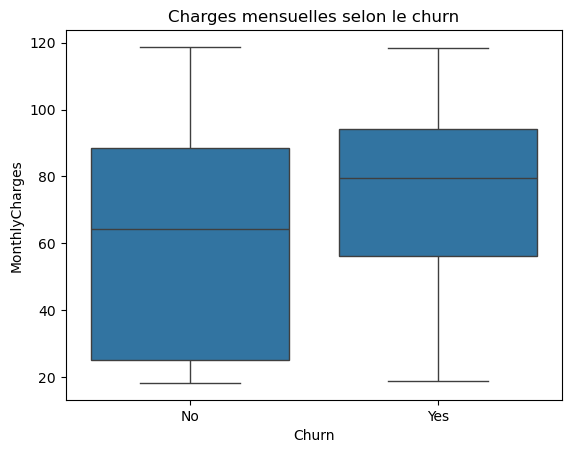

In [17]:
# Distribution du montant facturé par mois selon le churn
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Charges mensuelles selon le churn")
plt.show()

### 2.5 Churn et service internet

In [18]:
# Répartition des types de service internet
df["InternetService"].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [19]:
# Proportion de churn (en %) selon le type de service internet
pd.crosstab(df["InternetService"], df["Churn"], normalize="index") * 100

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


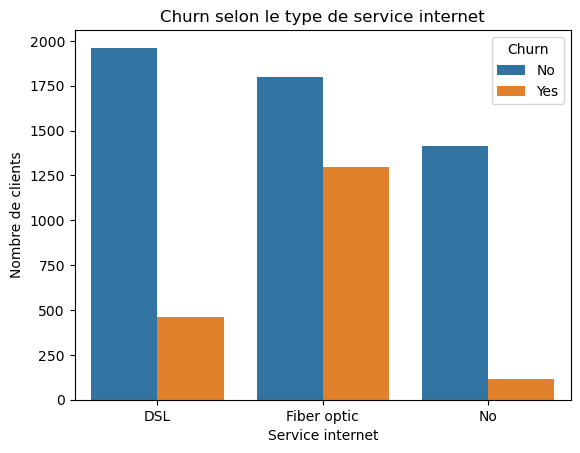

In [20]:
# Churn selon le type de service internet
sns.countplot(data=df, x="InternetService", hue="Churn")
plt.title("Churn selon le type de service internet")
plt.xlabel("Service internet")
plt.ylabel("Nombre de clients")
plt.show()

### 2.6 Churn et mode de paiement

In [21]:
# Répartition des modes de paiement
df["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [22]:
# Proportion de churn (en %) selon le mode de paiement
pd.crosstab(df["PaymentMethod"], df["Churn"], normalize="index") * 100

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


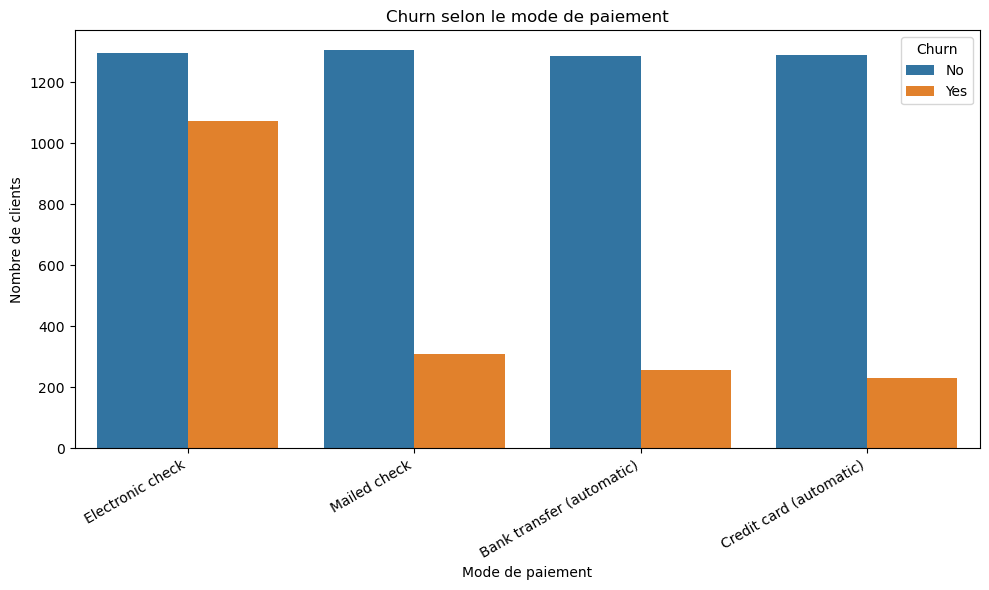

In [23]:
# Churn selon le mode de paiement
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="PaymentMethod", hue="Churn")
plt.xticks(rotation=30, ha="right")
plt.title("Churn selon le mode de paiement")
plt.xlabel("Mode de paiement")
plt.ylabel("Nombre de clients")
plt.tight_layout()  # évite que les textes soient coupés
plt.show()

### 2.7 Churn et support technique

In [24]:
# Répartition du support technique
df["TechSupport"].value_counts()

TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

In [25]:
# Proportion de churn (en %) selon le support technique
pd.crosstab(df["TechSupport"], df["Churn"], normalize="index") * 100

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


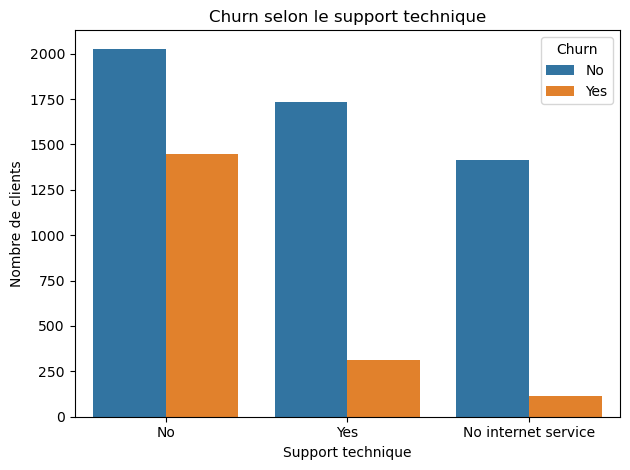

In [26]:
# Churn selon le support technique
sns.countplot(data=df, x="TechSupport", hue="Churn")
plt.title("Churn selon le support technique")
plt.xlabel("Support technique")
plt.ylabel("Nombre de clients")
plt.tight_layout()
plt.show()

### 2.8 Synthèse de l'exploration

- **Ancienneté :** les clients qui résilient sont plus récents (18 mois en moyenne contre 38 mois pour ceux qui restent).
- **Contrat :** le churn atteint environ 43 % pour les contrats mensuels, contre 11 % pour 1 an et 3 % pour 2 ans.
- **Charges mensuelles :** plus élevées chez les clients qui résilient (74 contre 61 en moyenne).
- **Internet :** environ 42 % de churn avec la fibre optique, contre 19 % avec le DSL et 7 % sans internet.
- **Paiement :** le chèque électronique se détache (environ 45 % de churn), contre 15 à 19 % pour les autres modes.
- **Support technique :** environ 42 % de churn sans support technique, contre 15 % avec.


Ces observations sont descriptives : elles seront vérifiées par le modèle dans la section 9.

## 3. Nettoyage des données

### 3.1 Valeurs manquantes

In [27]:
# Pourcentage de valeurs manquantes par colonne
df.isna().mean() * 100

customerID          0.0
gender              0.0
SeniorCitizen       0.0
Partner             0.0
Dependents          0.0
tenure              0.0
PhoneService        0.0
MultipleLines       0.0
InternetService     0.0
OnlineSecurity      0.0
OnlineBackup        0.0
DeviceProtection    0.0
TechSupport         0.0
StreamingTV         0.0
StreamingMovies     0.0
Contract            0.0
PaperlessBilling    0.0
PaymentMethod       0.0
MonthlyCharges      0.0
TotalCharges        0.0
Churn               0.0
dtype: float64

In [28]:
# TotalCharges devrait être numérique : vérification de son type et de ses valeurs
print(df["TotalCharges"].dtype)
df["TotalCharges"].value_counts().head()

object


TotalCharges
         11
20.2     11
19.75     9
20.05     8
19.9      8
Name: count, dtype: int64

In [29]:
# Conversion en numérique.
# errors="coerce" transforme chaque valeur non convertible en NaN au lieu de lever une erreur
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [30]:
# Nombre et pourcentage de valeurs manquantes créées par la conversion
print(df["TotalCharges"].isna().sum())
print(df["TotalCharges"].isna().mean() * 100)

11
0.1561834445548772


In [31]:
# Profil des clients dont TotalCharges est manquant
df[df["TotalCharges"].isna()][["TotalCharges", "tenure", "Churn", "Contract"]]

,TotalCharges,tenure,Churn,Contract
488,NaN,0,No,Two year
753,NaN,0,No,Two year
936,NaN,0,No,Two year
1082,NaN,0,No,Two year
1340,NaN,0,No,Two year
3331,NaN,0,No,Two year
3826,NaN,0,No,Two year
4380,NaN,0,No,Two year
5218,NaN,0,No,One year
6670,NaN,0,No,Two year


Les clients ayant un *TotalCharges* absent ont une ancienneté nulle, ce qui est cohérent : ils n'ont pas encore accumulé de montant facturé. On peut donc remplacer leur *TotalCharges* par 0.

In [32]:
# Vérification : ces clients ont bien un tarif mensuel positif
df[df["TotalCharges"].isna()]["MonthlyCharges"]

488     52.55
753     20.25
936     80.85
1082    25.75
1340    56.05
3331    19.85
3826    25.35
4380    20.00
5218    19.70
6670    73.35
6754    61.90
Name: MonthlyCharges, dtype: float64

##### `MonthlyCharges` est positif : ces clients ont un tarif mensuel mais pas encore de total cumulé enregistré.

In [33]:
# Remplacement des NaN de TotalCharges par 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Vérification
print(df["TotalCharges"].isna().sum())
print(df["TotalCharges"].dtype)

0
float64


### 3.2 Doublons

In [34]:
# Lignes entièrement dupliquées
print("Lignes dupliquées :", df.duplicated().sum())

# Identifiants clients dupliqués
print("customerID dupliqués :", df["customerID"].duplicated().sum())

Lignes dupliquées : 0
customerID dupliqués : 0


## 4. Préparation des données

### 4.1 Séparation des variables explicatives (X) et de la cible (y)

In [35]:
# customerID est un identifiant (sans valeur prédictive) : on le retire avec la cible
# D’un point de vue marketing, aucune raison ne pourrait justifier l’influence du Churn par le genre. Cette variable ne sera donc pas utilisée pour les différentes analyses. 
y = df["Churn"]
X = df.drop(columns=["customerID", "gender", "Churn"])

print(X.shape)
print(y.shape)

(7043, 18)
(7043,)


In [36]:
# Types des variables explicatives
X.dtypes

SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
dtype: object

In [37]:
# Variables numériques
# Remarque : SeniorCitizen est stockée en 0/1 mais sera traitée comme catégorielle (voir 4.3)
X.select_dtypes(include="number").columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')

In [38]:
# Variables catégorielles (type texte)
X.select_dtypes(include="object").columns

Index(['Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='object')

### 4.2 Séparation train / test

On ne doit surtout pas encoder ni transformer les données en regardant l'ensemble du dataset avant de le séparer, car cela provoque une **fuite de données (*data leakage*)**.

Le pipeline suivi est : **Dataset → X/y → Train/Test split → Prétraitement → Modèle → Évaluation**.

La variable `y` (Churn) est déséquilibrée. Avec un split totalement aléatoire, la proportion de `Yes` pourrait différer entre train et test. On utilise donc `stratify=y` pour conserver à peu près la même proportion de churn dans les deux ensembles.

In [39]:
# Séparation 80 % / 20 %, stratifiée sur la cible
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(5634, 18) (1409, 18)
(5634,) (1409,)


In [40]:
# Vérification : proportions de churn (en %) dans le train et dans le test
print("Train :")
print(y_train.value_counts(normalize=True) * 100)
print("\nTest :")
print(y_test.value_counts(normalize=True) * 100)

Train :
Churn
No     73.464679
Yes    26.535321
Name: proportion, dtype: float64

Test :
Churn
No     73.456352
Yes    26.543648
Name: proportion, dtype: float64


### 4.3 Prétraitement

- **Variables numériques** : standardisation avec `StandardScaler()`.
- **Variables catégorielles** : encodage *One-Hot*. `handle_unknown="ignore"` permet de gérer une modalité présente dans le test mais absente du train.

In [41]:
# Liste des variables par type
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = ["SeniorCitizen", "Partner", "Dependents", "PhoneService","MultipleLines", "InternetService", "OnlineSecurity", 
                        "OnlineBackup","DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", 
                        "PaymentMethod"]

In [42]:
# Création du ColumnTransformer
preprocessor = ColumnTransformer(transformers=[("num", StandardScaler(), numeric_features),
                                               ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)])

In [43]:
# fit_transform sur le train : on apprend les paramètres (moyennes, catégories) puis on transforme
X_train_encoded = preprocessor.fit_transform(X_train)

# transform sur le test : on n'apprend rien, on réutilise ce qui a été appris sur le train : pour éviter le data leakage)
X_test_encoded = preprocessor.transform(X_test)

print("Avant encodage :", X_train.shape, X_test.shape)
print("Après encodage :", X_train_encoded.shape, X_test_encoded.shape)

Avant encodage : (5634, 18) (1409, 18)
Après encodage : (5634, 44) (1409, 44)


On passe de 18 variables explicatives à 44, car le One-Hot Encoding transforme chaque modalité des variables catégorielles en une colonne.

## 5. Modèles de base

### 5.1 Régression logistique (seuil par défaut : 0,5)

In [44]:
# Initialisation du modèle 
model = LogisticRegression(max_iter=1000)

In [45]:
# Entrainement du modèle 
model.fit(X_train_encoded, y_train)


LogisticRegression(max_iter=1000)

In [46]:
# Prédictions 
y_pred = model.predict(X_test_encoded)

In [47]:
# Matrice de confusion (lignes : valeurs réelles, colonnes : prédictions)
# labels=["No", "Yes"] fixe l'ordre des classes
cm = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])
print(cm)

[[926 109]
 [165 209]]


In [48]:
# Probabilités de la classe positive (Yes) sur l'entraînement et sur le test
proba_train = model.predict_proba(X_train_encoded)[:, 1]
proba_test = model.predict_proba(X_test_encoded)[:, 1]

# AUC : y == "Yes" convertit la cible en booléen (Yes = 1, No = 0)
auc_train = roc_auc_score(y_train == "Yes", proba_train)
auc_test = roc_auc_score(y_test == "Yes", proba_test)

print(f"AUC entraînement : {auc_train:.4f}")
print(f"AUC test         : {auc_test:.4f}")


AUC entraînement : 0.8493
AUC test         : 0.8421


In [49]:
# Métriques d'évaluation
# pos_label="Yes" indique que la classe positive est "Yes" (client qui résilie)

print("Recall    :", recall_score(y_test, y_pred, pos_label="Yes"))
print("Precision :", precision_score(y_test, y_pred, pos_label="Yes"))
print("F1-score  :", f1_score(y_test, y_pred, pos_label="Yes"))

Recall    : 0.5588235294117647
Precision : 0.6572327044025157
F1-score  : 0.6040462427745664


### 5.2 Random Forest

In [50]:
# Entraînement et prédictions
rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train_encoded, y_train)
y_pred_rf = rf_model.predict(X_test_encoded)

In [51]:
# Matrice de confusion
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=["No", "Yes"])
print(cm_rf)

[[917 118]
 [191 183]]


In [52]:
# Probabilités de la classe positive (Yes) sur l'entraînement et sur le test
rf_proba_train = rf_model.predict_proba(X_train_encoded)[:, 1]
rf_proba_test = rf_model.predict_proba(X_test_encoded)[:, 1]

# AUC : y == "Yes" convertit la cible en booléen (Yes = 1, No = 0)
rf_auc_train = roc_auc_score(y_train == "Yes", rf_proba_train)
rf_auc_test = roc_auc_score(y_test == "Yes", rf_proba_test)

print(f"AUC entraînement : {rf_auc_train:.4f}")
print(f"AUC test         : {rf_auc_test:.4f}")


AUC entraînement : 0.9998
AUC test         : 0.8240


In [53]:
# Métriques d'évaluation
print("Recall    :", recall_score(y_test, y_pred_rf, pos_label="Yes"))
print("Precision :", precision_score(y_test, y_pred_rf, pos_label="Yes"))
print("F1-score  :", f1_score(y_test, y_pred_rf, pos_label="Yes"))

Recall    : 0.4893048128342246
Precision : 0.6079734219269103
F1-score  : 0.5422222222222223


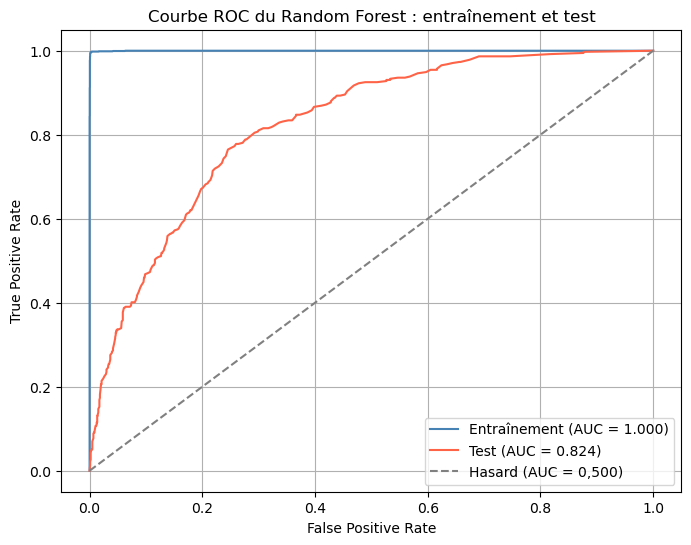

In [54]:
# Points des courbes ROC (y == "Yes" convertit la cible en booléen)
fpr_rf_train, tpr_rf_train, _ = roc_curve(y_train == "Yes", rf_proba_train)
fpr_rf_test, tpr_rf_test, _ = roc_curve(y_test == "Yes", rf_proba_test)

# Tracé des deux courbes (la diagonale correspond au hasard)
plt.figure(figsize=(8, 6))
plt.plot(fpr_rf_train, tpr_rf_train, color="steelblue", label=f"Entraînement (AUC = {rf_auc_train:.3f})")
plt.plot(fpr_rf_test, tpr_rf_test, color="tomato", label=f"Test (AUC = {rf_auc_test:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Hasard (AUC = 0,500)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Courbe ROC du Random Forest : entraînement et test")
plt.legend(loc="lower right")
plt.grid()
plt.show()

## 6. Seuil de décision et courbes d'évaluation

Le **seuil de décision** est la probabilité à partir de laquelle un client est classé « à risque ». Il est fixé automatiquement à 0,5, mais ce n'est pas forcément le meilleur choix.

### 6.1 Probabilités de la régression logistique

In [55]:
# Probabilité estimée pour chaque client d'appartenir à la classe positive (Yes)
y_proba = model.predict_proba(X_test_encoded)[:, 1]
y_proba[:10]  # les dix premières probabilités

array([0.04487806, 0.68643942, 0.05956606, 0.39949813, 0.02179105,
       0.60595077, 0.4513005 , 0.12947006, 0.00292975, 0.39256726])

### 6.2 Effet du seuil

In [56]:
# Exemple : seuil abaissé à 0,30
y_pred_30 = np.where(y_proba >= 0.30, "Yes", "No")

print("Recall    :", recall_score(y_test, y_pred_30, pos_label="Yes"))
print("Precision :", precision_score(y_test, y_pred_30, pos_label="Yes"))
print("F1-score  :", f1_score(y_test, y_pred_30, pos_label="Yes"))

Recall    : 0.7540106951871658
Precision : 0.5193370165745856
F1-score  : 0.6150490730643402


In [57]:
# Balayage de plusieurs seuils (avec la régression logistique)
seuils_test = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

for seuil in seuils_test:
    y_pred_seuil = np.where(y_proba >= seuil, "Yes", "No")
    print(f"Seuil {seuil:.2f} | "
          f"Recall : {recall_score(y_test, y_pred_seuil, pos_label='Yes'):.3f} | "
          f"Precision : {precision_score(y_test, y_pred_seuil, pos_label='Yes'):.3f} | "
          f"F1 : {f1_score(y_test, y_pred_seuil, pos_label='Yes'):.3f}")

Seuil 0.20 | Recall : 0.856 | Precision : 0.469 | F1 : 0.605
Seuil 0.30 | Recall : 0.754 | Precision : 0.519 | F1 : 0.615
Seuil 0.40 | Recall : 0.666 | Precision : 0.568 | F1 : 0.613
Seuil 0.50 | Recall : 0.559 | Precision : 0.657 | F1 : 0.604
Seuil 0.60 | Recall : 0.398 | Precision : 0.710 | F1 : 0.510
Seuil 0.70 | Recall : 0.179 | Precision : 0.736 | F1 : 0.288


### 6.3 Courbe Precision-Recall et choix du seuil

L'**Average Precision (AP)** résume la courbe en un seul chiffre. Le point de comparaison est le taux de churn (ligne pointillée) : un modèle sans capacité de prédiction aurait un AP proche de cette valeur.

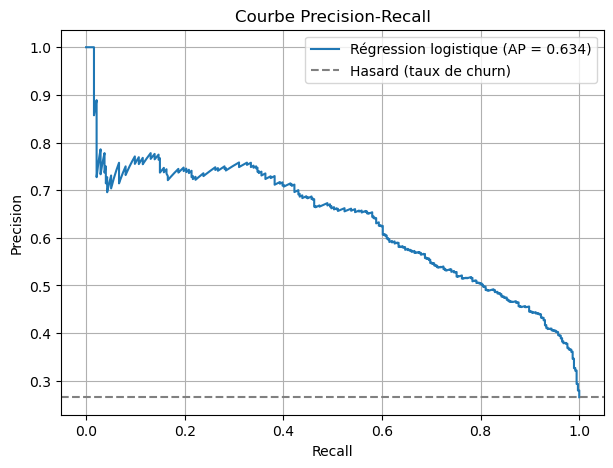

In [58]:
# Calcul de la courbe (y_proba vient de la régression logistique classique)
y_test_bin = (y_test == "Yes").astype(int)   # Yes = 1, No = 0

precision, recall, thresholds = precision_recall_curve(y_test_bin, y_proba)
ap = average_precision_score(y_test_bin, y_proba)

# Tracé
plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"Régression logistique (AP = {ap:.3f})")
plt.axhline(y_test_bin.mean(), color="gray", linestyle="--", label="Hasard (taux de churn)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Courbe Precision-Recall")
plt.legend()
plt.grid()
plt.show()

In [59]:
# Seuil qui maximise le F1-score
f1_scores = 2 * precision * recall / (precision + recall)
best = np.argmax(f1_scores[:-1])   

best_threshold = thresholds[best]
print(f"Meilleur seuil : {best_threshold:.3f}")
print(f"Recall : {recall[best]:.3f} |Precision : {precision[best]:.3f}| F1 : {f1_scores[best]:.3f}")

Meilleur seuil : 0.278
Recall : 0.781 |Precision : 0.518| F1 : 0.623


Le F1 est très plat entre 0,25 et 0,45, autour de 0,61 : choisir précisément le seuil qui le maximise compte donc peu. C'est le **coût métier** qui doit décider :

- Si une campagne de rétention est peu coûteuse et qu'un client perdu coûte cher : seuil bas (entre 0,20 et 0,30), pour attraper environ 75 à 80 % des départs.
- Si le budget est limité (on ne peut contacter que quelques centaines de clients) : seuil plus haut (vers 0,40 ou 0,50), pour que chaque appel soit mieux ciblé.

Le ROC-AUC mesure la capacité du modèle à **distinguer** les clients `Yes` des clients `No` sur l'ensemble des seuils : il ne dépend pas du seuil de classification. À l'inverse, la precision et le recall dépendent du seuil choisi. Il est donc utile de regarder à la fois les métriques au seuil retenu et une métrique indépendante du seuil.

La régression logistique obtient un ROC-AUC d'environ 0,84 sur l'échantillon de test, ce qui indique une bonne capacité à discriminer les clients qui résilient de ceux qui restent.

## 7. Gestion du déséquilibre des classes

Pour la cible `Churn`, on avait constaté : **No : 73,5 %** et **Yes : 26,5 %**. Le modèle voit donc beaucoup plus de clients qui restent que de clients qui résilient.

Trois leviers sont comparés : la **pondération des classes**, le **rééchantillonnage** du jeu d'entraînement, et le **réglage du seuil** (section 6).

### 7.1 Pondération des classes

`class_weight="balanced"` indique au modèle de tenir compte de la fréquence de chaque classe : poids plus faible pour `No`, plus élevé pour `Yes`. L'objectif est de ne pas laisser la classe majoritaire dominer l'apprentissage.

In [60]:
# Régression logistique avec pondération des classes
balanced_model = LogisticRegression(max_iter=2000, class_weight="balanced")
balanced_model.fit(X_train_encoded, y_train)
y_pred_balanced = balanced_model.predict(X_test_encoded)

In [61]:
# Matrice de confusion
cm_balanced = confusion_matrix(y_test, y_pred_balanced, labels=["No", "Yes"])
print(cm_balanced)

[[745 290]
 [ 81 293]]


In [62]:
# Probabilités de la classe positive (Yes) sur l'entraînement et sur le test
balanced_proba_train = balanced_model.predict_proba(X_train_encoded)[:, 1]
balanced_proba_test = balanced_model.predict_proba(X_test_encoded)[:, 1]

# AUC : y == "Yes" convertit la cible en booléen (Yes = 1, No = 0)
balanced_auc_train = roc_auc_score(y_train == "Yes", balanced_proba_train)
balanced_auc_test = roc_auc_score(y_test == "Yes", balanced_proba_test)

print(f"AUC entraînement : {balanced_auc_train:.4f}")
print(f"AUC test         : {balanced_auc_test:.4f}")


AUC entraînement : 0.8492
AUC test         : 0.8418


In [63]:
# Métriques d'évaluation
print("Régression logistique équilibrée")
print("-" * 40)
print("Recall :", round(recall_score(y_test, y_pred_balanced, pos_label="Yes"), 4))
print("Precision :", round(precision_score(y_test, y_pred_balanced, pos_label="Yes"), 4))
print("F1-score :", round(f1_score(y_test, y_pred_balanced, pos_label="Yes"), 4))

Régression logistique équilibrée
----------------------------------------
Recall : 0.7834
Precision : 0.5026
F1-score : 0.6123


Ce modèle classe davantage de clients fidèles comme susceptibles de partir : **290 fausses alertes**, contre **109** pour la régression logistique initiale.

C'est un compromis important en entreprise : veut-on surtout éviter de manquer les clients qui risquent de partir, ou limiter les fausses alertes et le coût des campagnes de fidélisation ?

**Choisir le modèle selon l'objectif métier**
- *Capacité à distinguer Yes et No* : la régression logistique initiale est la meilleure.
- *Détecter le maximum de clients susceptibles de partir* : la régression logistique équilibrée est la plus intéressante.
- *Compromis entre precision et détection* : le F1-score permet de comparer les deux objectifs.

Pour un opérateur télécom, manquer un client qui risque de résilier peut coûter cher : le modèle équilibré est donc une piste intéressante, même si ses fausses alertes sont plus nombreuses.

### 7.2 Rééchantillonnage du jeu d'entraînement

Trois techniques sont comparées : sur-échantillonnage aléatoire, SMOTE (création de clients synthétiques) et sous-échantillonnage aléatoire.

**Règle essentielle :** le rééchantillonnage ne s'applique **qu'au jeu d'entraînement**, pas au jeu de test.

In [64]:
samplers = {
    "Sur-échantillonnage aléatoire": RandomOverSampler(random_state=42),
    "SMOTE": SMOTE(random_state=42),
    "Sous-échantillonnage aléatoire": RandomUnderSampler(random_state=42),
}

results = []
resampled = {}   # on garde prédictions et probabilités pour le tableau final (section 8)

for name, sampler in samplers.items():
    # Rééchantillonnage du train uniquement (le test reste intact)
    X_res, y_res = sampler.fit_resample(X_train_encoded, y_train)

    m = LogisticRegression(max_iter=2000)
    m.fit(X_res, y_res)

    pred = m.predict(X_test_encoded)
    proba = m.predict_proba(X_test_encoded)[:, 1]
    resampled[name] = (pred, proba)

    # Probabilités sur le train d'origine (non rééchantillonné)
    proba_train = m.predict_proba(X_train_encoded)[:, 1]

    results.append({
        "Méthode": name,
        "Precision": round(precision_score(y_test, pred, pos_label="Yes"), 4),
        "Recall": round(recall_score(y_test, pred, pos_label="Yes"), 4),
        "F1-score": round(f1_score(y_test, pred, pos_label="Yes"), 4),
        "AUC train":round(roc_auc_score(y_train == "Yes", proba_train), 4),
        "AUC test": round(roc_auc_score(y_test == "Yes", proba), 4),
    })

pd.DataFrame(results)

,Méthode,Precision,Recall,F1-score,AUC train,AUC test
0,Sur-échantillonnage aléatoire,0.5000,0.7888,0.6120,0.8490,0.8424
1,SMOTE,0.5000,0.7941,0.6136,0.8486,0.8395
2,Sous-échantillonnage aléatoire,0.5095,0.7861,0.6183,0.8484,0.8429


Toutes les techniques de rééchantillonnage produisent le même effet : aucun sur-apprentissage, le recall monte nettement (environ 0,56 → 0,79) et la precision baisse (environ 0,66 → 0,50). Elles déplacent le compromis precision/recall, comme le font la pondération des classes et le réglage du seuil.

## 8. Tableau récapitulatif et choix du modèle final

Tous les essais sont regroupés dans un seul tableau, avec le **seuil** utilisé pour chaque ligne : les lignes à 0,50 et la ligne à seuil ajusté ne sont comparables qu'en gardant cette différence en tête.

In [65]:
# Fonction qui calcule toutes les métriques d'une ligne du tableau
def evaluate(famille, modele, y_pred, y_proba, seuil=0.50):
    return {
        "Famille": famille,
        "Modèle": modele,
        "Seuil": seuil,
        "Recall": recall_score(y_test, y_pred, pos_label="Yes"),
        "Precision": precision_score(y_test, y_pred, pos_label="Yes"),
        "F1-score": f1_score(y_test, y_pred, pos_label="Yes"),
        "AUC": roc_auc_score(y_test == "Yes", y_proba),
    }

# Prédictions avec le seuil ajusté (régression logistique classique)
pred_thr = np.where(y_proba >= best_threshold, "Yes", "No")

rows = [
    # Modèles de base
    evaluate("Base", "Régression logistique", y_pred, model.predict_proba(X_test_encoded)[:, 1]),
    evaluate("Base", "Random Forest", y_pred_rf, rf_model.predict_proba(X_test_encoded)[:, 1]),
    # Pondération des classes
    evaluate("Pondération", "Rég. logistique équilibrée", y_pred_balanced, balanced_model.predict_proba(X_test_encoded)[:, 1]),
]

# Rééchantillonnage (régression logistique)
for name in ["Sur-échantillonnage aléatoire", "SMOTE", "Sous-échantillonnage aléatoire"]:
    pred, proba = resampled[name]
    rows.append(evaluate("Rééchantillonnage", name, pred, proba))

# Réglage du seuil (régression logistique classique)
rows.append(evaluate("Seuil ajusté", "Régression logistique", pred_thr, y_proba, seuil=best_threshold))

summary = pd.DataFrame(rows).round(3)

# La ligne retenue est mise en gras
summary.style.apply(
    lambda row: ["font-weight: bold"] * len(row) if row["Famille"] == "Seuil ajusté" else [""] * len(row),
    axis=1
)

,Famille,Modèle,Seuil,Recall,Precision,F1-score,AUC
0,Base,Régression logistique,0.500000,0.559000,0.657000,0.604000,0.842000
1,Base,Random Forest,0.500000,0.489000,0.608000,0.542000,0.824000
2,Pondération,Rég. logistique équilibrée,0.500000,0.783000,0.503000,0.612000,0.842000
3,Rééchantillonnage,Sur-échantillonnage aléatoire,0.500000,0.789000,0.500000,0.612000,0.842000
4,Rééchantillonnage,SMOTE,0.500000,0.794000,0.500000,0.614000,0.840000
5,Rééchantillonnage,Sous-échantillonnage aléatoire,0.500000,0.786000,0.510000,0.618000,0.843000
6,Seuil ajusté,Régression logistique,0.278000,0.781000,0.518000,0.623000,0.842000


**Modèle retenu : régression logistique classique avec un seuil de décision ajusté (environ 0,28).**

- Le choix de ce modèle repose sur l'amélioration du compromis entre la précision et le rappel, mesuré notamment par le F1-score, tout en conservant une capacité de discrimination satisfaisante, évaluée par l'AUC.
- Contrairement à la pondération des classes et aux méthodes de rééchantillonnage, l'ajustement du seuil permet de modifier la règle de classification sans modifier les données utilisées pour entraîner le modèle. Cette approche est simple à mettre en œuvre et à expliquer dans un contexte métier.
- Enfin, la régression logistique conserve l'avantage d'être relativement simple à interpréter, notamment grâce à ses coefficients, présentés dans la section 9.

## 9. Facteurs associés au départ des clients

### 9.1 Coefficients de la régression logistique

In [66]:
# Coefficients du modèle et odds ratios (exp du coefficient)
feature_names = preprocessor.get_feature_names_out()

coef_df = pd.DataFrame({"Variable": feature_names, "Coefficient": model.coef_[0]})
coef_df["Odds ratio"] = np.exp(coef_df["Coefficient"])
coef_df["Abs"] = coef_df["Coefficient"].abs()

# Tri par importance absolue
coef_df = coef_df.sort_values(by="Abs", ascending=False).drop(columns="Abs")
coef_df.head(15).round(3)

,Variable,Coefficient,Odds ratio
0,num__tenure,-1.239,0.290
37,cat__Contract_Two year,-0.772,0.462
14,cat__InternetService_DSL,-0.647,0.524
15,cat__InternetService_Fiber optic,0.636,1.889
1,num__MonthlyCharges,-0.588,0.555
35,cat__Contract_Month-to-month,0.584,1.793
2,num__TotalCharges,0.516,1.676
38,cat__PaperlessBilling_No,-0.340,0.712
27,cat__TechSupport_No internet service,-0.298,0.743
18,cat__OnlineSecurity_No internet service,-0.298,0.743


### 9.2 Graphique des 12 variables les plus influentes

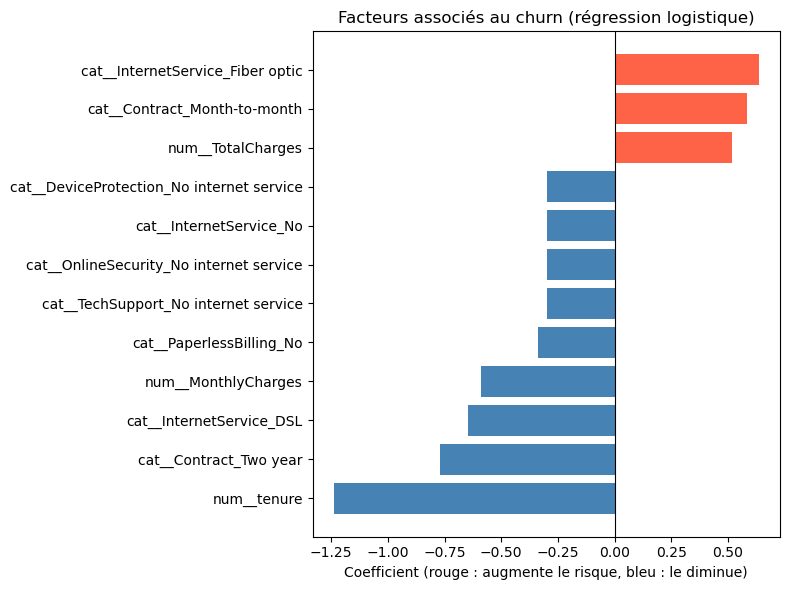

In [67]:
top = coef_df.head(12).sort_values(by="Coefficient")

plt.figure(figsize=(8, 6))
colors = ["tomato" if c > 0 else "steelblue" for c in top["Coefficient"]]
plt.barh(top["Variable"], top["Coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Facteurs associés au churn (régression logistique)")
plt.xlabel("Coefficient (rouge : augmente le risque, bleu : le diminue)")
plt.tight_layout()
plt.show()

### 9.3 Interprétation

- **Coefficient positif** (odds ratio supérieur à 1) : la variable est associée à un risque de départ plus élevé.
- **Coefficient négatif** (odds ratio inférieur à 1) : la variable est associée à un risque plus faible.
- L'odds ratio est `exp(coefficient)`. Un odds ratio de 1,9 signifie que les chances de résilier sont environ 1,9 fois plus élevées, toutes choses égales par ailleurs.
- Pour `tenure`, `MonthlyCharges` et `TotalCharges`, qui sont standardisées, l'odds ratio correspond à une augmentation de **1 écart-type**, pas d'une unité.

**Précautions de lecture**
- `MonthlyCharges`, `TotalCharges` et `tenure` sont fortement liées entre elles : leurs coefficients ne doivent pas être lus isolément.
- Les modalités « No internet service » portent toutes le même coefficient : c'est une même information répétée par l'encodage (clients sans internet).

Les clients les plus à risque ont un **contrat mensuel**, une **faible ancienneté** et un abonnement **fibre optique**. À l'inverse, l'engagement contractuel (contrat de 2 ans) et l'ancienneté sont les facteurs les plus protecteurs. Ces résultats décrivent des associations statistiques, pas des relations de cause à effet.

## 10. Conclusion et recommandations

**Résultats**
- La régression logistique surpasse le Random Forest sur ce jeu de données (AUC d'environ 0,84 contre 0,82).
- Pondération des classes, rééchantillonnage et réglage du seuil produisent un effet comparable sur le compromis precision/recall. Le **réglage du seuil** est retenu car il est plus simple et plus facile à justifier.
- Avec un seuil d'environ 0,28, le modèle détecte environ 78 % des clients qui vont résilier, mais seulement un client signalé sur deux part réellement.

**Recommandations métier**
1. Prioriser les clients en contrat mensuel et de faible ancienneté pour les actions de rétention.
2. Encourager le passage à un contrat annuel ou de 2 ans (offre, avantage tarifaire).
3. Examiner l'offre fibre optique (prix, qualité de service, concurrence).
4. Fixer le seuil avec les équipes métier, à partir du coût d'une action de rétention et de la valeur d'un client conservé.

**Limites et pistes d'amélioration**
- Une seule séparation train/test : une validation croisée donnerait une estimation plus stable.
- Pas de réglage des hyperparamètres ni d'autres modèles testés (gradient boosting, XGBoost, LightGBM).